# 04 — Huấn luyện, Đánh giá và Trích xuất Embedding: Mô hình NARM

Notebook này thực hiện trọn vẹn quy trình huấn luyện và đánh giá mô hình **NARM** (*Neural Attentive Session-based Recommendation — Li et al., CIKM 2017*) trên bộ dữ liệu **Diginetica** với **2 random seed (`2024`, `2025`)**.

## Đặc trưng kiến trúc của NARM và Giao thức thí nghiệm

1. **Kiến trúc Hybrid Global + Local Attention Encoder:**
   - **Global Encoder:** Lấy trạng thái ẩn cuối cùng $h_t$ của mạng GRU làm biểu diễn hành vi tuần tự tổng quát của phiên.
   - **Local Encoder (Attention):** Tính trọng số chú ý $\alpha_{tj} = v^\top \sigma(A_1 h_t + A_2 h_j)$ trên tất cả các bước trong phiên để trích xuất ý định chính (main purpose) $c_t = \sum_j \alpha_{tj} h_j$.
   - Ghép nối $[c_t; h_t]$, áp dụng `ct_dropout = 0.50` và chiếu tuyến tính về chiều `embedding_size = 64` trước khi nhân vô hướng với bảng `item_embedding`.
2. **Đảm bảo tính công bằng tuyệt đối với GRU4Rec và SASRec:**
   - Dùng chung tập `train_examples.parquet`, `validation_examples.parquet`, `test_examples.parquet`, `item_mapping.csv`.
   - Khóa cứng gradient và mask điểm (`-1e9`) đối với `padding_idx = 0` và `7.647` Controlled Cold items.
   - Xuất đủ 8 file chuẩn vào `runs/narm/seed_{2024,2025}/` và bảng cấp độ item vào `results/item_level/narm_seed{2024,2025}.parquet`.

## 1. Thiết lập môi trường, thiết bị (GPU/CPU) và đọc cấu hình

In [2]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án BTL-K03.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import FIGURES_DIR, ITEM_LEVEL_DIR, PROCESSED_DIGI_DIR, RUNS_DIR, TABLES_DIR, ensure_output_dirs
from btl_k03.utils import load_experiment_config, load_item_mapping, set_global_seed
from btl_k03.models import SessionPrefixDataset, build_model_from_config, train_and_evaluate_seed

ensure_output_dirs()

MODEL_NAME = "narm"
CONFIG = load_experiment_config(MODEL_NAME)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python executable : {sys.executable}")
print(f"PyTorch version   : {torch.__version__}")
print(f"Device            : {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Model architecture: {CONFIG['architecture']}")
print(f"Seeds             : {CONFIG['seeds']}")
print(f"Model params      : {json.dumps(CONFIG['model_params'], ensure_ascii=False)}")
print(f"Training config   : {json.dumps(CONFIG['training'], ensure_ascii=False)}")

Python executable : c:\Users\ASUS\AppData\Local\Programs\Python\Python312\python.exe
PyTorch version   : 2.14.1+cpu
Device            : cpu (CPU)
Model architecture: NARM
Seeds             : [2024, 2025]
Model params      : {"embedding_size": 64, "hidden_size": 128, "n_layers": 1, "embedding_dropout": 0.25, "ct_dropout": 0.5, "init_std": 0.02}
Training config   : {"loss_type": "CE", "optimizer": "adam", "learning_rate": 0.001, "weight_decay": 0.0, "grad_clip_norm": 5.0, "train_batch_size": 512, "eval_batch_size": 1024, "epochs": 30, "num_workers": 0, "pin_memory": true, "use_amp": true}


## 2. Kiểm tra dữ liệu đầu vào và mặt nạ Warm / Controlled Cold (`Option B`)

In [3]:
item_mapping = load_item_mapping(PROCESSED_DIGI_DIR)
train_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "train_examples.parquet")
val_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "validation_examples.parquet")
test_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_examples.parquet")
test_last_examples = pd.read_parquet(PROCESSED_DIGI_DIR / "test_last_item_examples.parquet")

n_total_catalog = len(item_mapping)
n_warm = int(item_mapping["is_trainable_warm"].sum())
n_cold = int(item_mapping["is_controlled_cold"].sum())

summary_input = pd.DataFrame([
    {"Chỉ tiêu": "Tổng số item trong bảng Embedding (ID 1..N)", "Giá trị": f"{n_total_catalog:,}"},
    {"Chỉ tiêu": "Số item Warm hợp lệ (is_trainable_warm = True)", "Giá trị": f"{n_warm:,}"},
    {"Chỉ tiêu": "Số item Controlled Cold 20% (is_controlled_cold = True)", "Giá trị": f"{n_cold:,}"},
    {"Chỉ tiêu": "Số mẫu Train (All-prefix)", "Giá trị": f"{len(train_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Validation Warm (All-prefix)", "Giá trị": f"{len(val_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm chính (All-prefix)", "Giá trị": f"{len(test_examples):,}"},
    {"Chỉ tiêu": "Số mẫu Test Warm phiên cuối (Last-item)", "Giá trị": f"{len(test_last_examples):,}"},
])
display(summary_input)

,Chỉ tiêu,Giá trị
0,Tổng số item trong bảng Embedding (ID 1..N),"37,583"
1,Số item Warm hợp lệ (is_trainable_warm = True),"29,936"
2,Số item Controlled Cold 20% (is_controlled_col...,"7,647"
3,Số mẫu Train (All-prefix),"498,849"
4,Số mẫu Validation Warm (All-prefix),"29,828"
5,Số mẫu Test Warm chính (All-prefix),"40,001"
6,Số mẫu Test Warm phiên cuối (Last-item),"12,791"


## 3. Khởi tạo kiến trúc NARM và Sanity Check khóa Gradient Cold Item

In [4]:
set_global_seed(2024)
sanity_model = build_model_from_config(CONFIG, item_mapping, DEVICE)
print(sanity_model)

sample_ds = SessionPrefixDataset(train_examples.head(64), max_seq_length=CONFIG["max_seq_length"])
sample_seq = sample_ds.sequences.to(DEVICE)
sample_len = sample_ds.lengths.to(DEVICE)
sample_target = sample_ds.targets_tensor.to(DEVICE)

sanity_model.zero_grad()
logits = sanity_model.full_sort_logits(sample_seq, sample_len, mask_cold_and_pad=True)
loss = torch.nn.functional.cross_entropy(logits, sample_target)
loss.backward()

grad_matrix = sanity_model.item_embedding.weight.grad.detach().cpu().numpy()
cold_ids = item_mapping.loc[item_mapping["is_controlled_cold"], "internal_item_id"].to_numpy()
warm_ids = item_mapping.loc[item_mapping["is_trainable_warm"], "internal_item_id"].to_numpy()

max_cold_grad = float(np.max(np.abs(grad_matrix[cold_ids])))
max_pad_grad = float(np.max(np.abs(grad_matrix[0])))
max_warm_grad = float(np.max(np.abs(grad_matrix[warm_ids])))

print(f"\n[SANITY CHECK GRADIENT - NARM]")
print(f"- Loss khởi tạo (Cross-Entropy trên 29,936 warm items): {loss.item():.4f} (Lý thuyết ~ ln(29936) = {np.log(n_warm):.4f})")
print(f"- Max |grad| của hàng Padding (ID 0)                  : {max_pad_grad:.10f}")
print(f"- Max |grad| của 7,647 hàng Controlled Cold           : {max_cold_grad:.10f}")
print(f"- Max |grad| của 29,936 hàng Trainable Warm           : {max_warm_grad:.10f}")
assert max_cold_grad == 0.0 and max_pad_grad == 0.0 and max_warm_grad > 0.0
del sanity_model

NARMModel(
  (item_embedding): Embedding(37584, 64, padding_idx=0)
  (emb_dropout): Dropout(p=0.25, inplace=False)
  (gru): GRU(64, 128, bias=False, batch_first=True)
  (a_1): Linear(in_features=128, out_features=128, bias=False)
  (a_2): Linear(in_features=128, out_features=128, bias=False)
  (v_t): Linear(in_features=128, out_features=1, bias=False)
  (ct_dropout): Dropout(p=0.5, inplace=False)
  (b): Linear(in_features=256, out_features=64, bias=False)
)

[SANITY CHECK GRADIENT - NARM]
- Loss khởi tạo (Cross-Entropy trên 29,936 warm items): 10.3069 (Lý thuyết ~ ln(29936) = 10.3068)
- Max |grad| của hàng Padding (ID 0)                  : 0.0000000000
- Max |grad| của 7,647 hàng Controlled Cold           : 0.0000000000
- Max |grad| của 29,936 hàng Trainable Warm           : 0.0019260375


D:\DA3-ThienlechdophobientrongkhonggianEmbedding\src\btl_k03\models.py:473: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  warm_mask[warm_ids] = True


## 4. Huấn luyện NARM trên 2 Seed (`2024` và `2025`)

In [5]:
MAX_EPOCHS_OVERRIDE = None  # Đặt bằng None để chạy full theo config (30 epochs + Early Stopping)

run_outputs = {}
for seed in CONFIG["seeds"]:
    run_outputs[seed] = train_and_evaluate_seed(
        model_name=MODEL_NAME,
        seed=seed,
        config=CONFIG,
        processed_dir=PROCESSED_DIGI_DIR,
        max_epochs_override=MAX_EPOCHS_OVERRIDE,
    )

2026-10-25 09:33:02 | INFO | ========================================================================
2026-10-25 09:33:02 | INFO | BẮT ĐẦU HUẤN LUYỆN MÔ HÌNH NARM | SEED = 2024
2026-10-25 09:33:02 | INFO | Thiết bị chạy (Device) : cpu
2026-10-25 09:33:02 | INFO | Thư mục lưu kết quả    : D:\DA3-ThienlechdophobientrongkhonggianEmbedding\runs\narm\seed_2024
2026-10-25 09:33:02 | INFO | ========================================================================
2026-10-25 09:33:03 | INFO | Tổng số item trong bảng Embedding: 37,583 (+1 hàng padding 0) | Warm trainable: 29,936 | Controlled cold (đóng băng): 7,647
2026-10-25 09:33:03 | INFO | Tổng số tham số mô hình: 2,528,384


[NARM seed=2024] Epoch 01/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 09:38:31 | INFO | Epoch 01/30 | Loss: 9.1015 | Val Recall@20: 0.1717 | Val MRR@20: 0.0463 | Val NDCG@20: 0.0735 | Time: 325.9s [BEST]


[NARM seed=2024] Epoch 02/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 09:43:56 | INFO | Epoch 02/30 | Loss: 6.9046 | Val Recall@20: 0.4146 | Val MRR@20: 0.1241 | Val NDCG@20: 0.1875 | Time: 325.3s [BEST]


...

2026-10-25 14:21:50 | INFO | Epoch 23/30 | Loss: 4.3323 | Val Recall@20: 0.5655 | Val MRR@20: 0.1990 | Val NDCG@20: 0.2802 | Time: 317.8s 


[NARM seed=2025] Epoch 24/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 14:27:06 | INFO | Epoch 24/30 | Loss: 4.3110 | Val Recall@20: 0.5679 | Val MRR@20: 0.2004 | Val NDCG@20: 0.2818 | Time: 316.2s 


[NARM seed=2025] Epoch 25/30:   0%|          | 0/975 [00:00<?, ?it/s]

2026-10-25 14:32:26 | INFO | Epoch 25/30 | Loss: 4.2898 | Val Recall@20: 0.5684 | Val MRR@20: 0.1994 | Val NDCG@20: 0.2810 | Time: 319.5s 
2026-10-25 14:32:26 | INFO | Early stopping kích hoạt tại epoch 25 (không cải thiện mrr@20 sau 5 epochs). Best epoch = 20 (0.2045).
2026-10-25 14:32:26 | INFO | Kiểm định Option B: Độ lệch tối đa của 7,647 Controlled Cold Embeddings = 0.00000000 (Chưa huấn luyện 100%).
2026-10-25 14:32:39 | INFO | ------------------------------------------------------------------------
2026-10-25 14:32:39 | INFO | [KẾT QUẢ TEST WARM] Recall@20: 0.5618 | MRR@20: 0.1976 | NDCG@20: 0.2782
2026-10-25 14:32:39 | INFO | [TEST LAST-ITEM]    Recall@20: 0.5640 | MRR@20: 0.2139 | NDCG@20: 0.2917
2026-10-25 14:32:39 | INFO | [POPULARITY BIAS]   Coverage_warm@20: 0.8960 | Gini_warm@20: 0.7019 | ARP@20: 77.11
2026-10-25 14:32:39 | INFO | Đã xuất đầy đủ kết quả vào: D:\DA3-ThienlechdophobientrongkhonggianEmbedding\runs\narm\seed_2025 và D:\DA3-ThienlechdophobientrongkhonggianEmbe

## 5. Tổng hợp kết quả chất lượng gợi ý (Warm-item Accuracy vs. Cold-start Impact)

In [6]:
acc_rows = []
stratified_frames = []
cold_diag_rows = []

for seed, out in run_outputs.items():
    tm = out["test_metrics"]
    w_all = tm["test_warm_all_prefix"]
    w_last = tm["test_warm_last_item"]
    acc_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "best_epoch": tm["best_epoch"],
        "val_best_mrr@20": tm["best_validation_score"],
        "test_warm_recall@20": w_all["recall@20"],
        "test_warm_mrr@20": w_all["mrr@20"],
        "test_warm_ndcg@20": w_all["ndcg@20"],
        "test_last_recall@20": w_last["recall@20"],
        "test_last_mrr@20": w_last["mrr@20"],
        "test_last_ndcg@20": w_last["ndcg@20"],
        "cold_max_drift": tm["cold_embedding_max_abs_drift"],
    })
    strat_df = out["test_stratified_df"].copy()
    strat_df.insert(0, "seed", seed)
    stratified_frames.append(strat_df)
    cold_diag_rows.append({"seed": seed, **tm["cold_start_diagnostic"]})

acc_df = pd.DataFrame(acc_rows)
print("=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA NARM TRÊN TẬP TEST WARM ===")
display(acc_df)

print("\n=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===")
display(pd.concat(stratified_frames, ignore_index=True))

print("\n=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===")
display(pd.DataFrame(cold_diag_rows))

=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN CỦA NARM TRÊN TẬP TEST WARM ===


,model,seed,best_epoch,val_best_mrr@20,test_warm_recall@20,test_warm_mrr@20,test_warm_ndcg@20,test_last_recall@20,test_last_mrr@20,test_last_ndcg@20,cold_max_drift
0,NARM,2024,15,0.2036,0.5632,0.1980,0.2789,0.5686,0.2149,0.2936,0.0000
1,NARM,2025,20,0.2045,0.5618,0.1976,0.2782,0.5640,0.2139,0.2917,0.0000



=== BẢNG 2: ĐỘ CHÍNH XÁC TÁCH THEO NHÓM ĐỘ PHỔ BIẾN CỦA TARGET (POPULAR / MEDIUM / RARE) ===


,seed,target_group,num_examples,example_share_pct,recall@20,mrr@20,ndcg@20
0,2024,all_warm,40001,100.0000,0.5632,0.1980,0.2789
1,2024,popular,23091,57.7261,0.6527,0.2423,0.3340
2,2024,medium,14300,35.7491,0.4622,0.1433,0.2129
3,2024,rare,2610,6.5248,0.3241,0.1059,0.1533
4,2025,all_warm,40001,100.0000,0.5618,0.1976,0.2782
5,2025,popular,23091,57.7261,0.6542,0.2426,0.3344
6,2025,medium,14300,35.7491,0.4550,0.1416,0.2099
7,2025,rare,2610,6.5248,0.3307,0.1062,0.1552



=== BẢNG 3: ĐỐI CHỨNG HIỆU NĂNG KHI BAO GỒM 20% CONTROLLED COLD & NATURAL COLD TRONG TEST FULL ===


,seed,full_test_sessions_len_ge_2,full_test_all_prefix_targets,warm_evaluated_targets,controlled_cold_targets_in_test,controlled_cold_target_share_pct,natural_cold_targets_in_test,natural_cold_target_share_pct,other_unseen_or_filtered_targets,warm_target_coverage_in_full_test_pct,warm_recall@20,warm_mrr@20,warm_ndcg@20,effective_full_test_recall@20_with_cold_zero,effective_full_test_mrr@20_with_cold_zero,effective_full_test_ndcg@20_with_cold_zero
0,2024,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5632,0.1980,0.2789,0.3160,0.1111,0.1565
1,2025,17155,71290,40001,11614,16.2912,4745,6.6559,11073,56.1103,0.5618,0.1976,0.2782,0.3152,0.1109,0.1561


## 6. Chỉ số Thiên lệch độ phổ biến ở đầu ra (`Coverage@20`, `Gini@20`, `ARP@20`)

In [7]:
bias_rows = []
exposure_frames = []

for seed, out in run_outputs.items():
    pb = out["test_metrics"]["popularity_bias"]
    bias_rows.append({
        "model": MODEL_NAME.upper(),
        "seed": seed,
        "coverage_warm@20": pb["coverage_warm@20"],
        "coverage_full@20": pb["coverage_full@20"],
        "gini_warm@20": pb["gini_warm@20"],
        "gini_full@20": pb["gini_full@20"],
        "arp@20": pb["arp@20"],
        "arp_log1p@20": pb["arp_log1p@20"],
        "popular_exposure_pct": pb["popular_group_exposure_share_pct"],
        "rare_exposure_pct": pb["rare_group_exposure_share_pct"],
    })
    exp_df = out["group_exposure_df"].copy()
    exp_df.insert(0, "seed", seed)
    exposure_frames.append(exp_df)

print("=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA NARM ===")
display(pd.DataFrame(bias_rows))

print("\n=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===")
display(pd.concat(exposure_frames, ignore_index=True))

=== BẢNG 4: CHỈ SỐ POPULARITY BIAS ĐẦU RA CỦA NARM ===


,model,seed,coverage_warm@20,coverage_full@20,gini_warm@20,gini_full@20,arp@20,arp_log1p@20,popular_exposure_pct,rare_exposure_pct
0,NARM,2024,0.8755,0.6974,0.7102,0.7692,76.0239,3.7695,64.0604,4.1149
1,NARM,2025,0.8960,0.7137,0.7019,0.7625,77.1078,3.7714,64.2308,4.2114



=== BẢNG 5: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 THEO NHÓM POPULAR / MEDIUM / RARE / COLD ===


,seed,popularity_group,catalog_items,warm_catalog_share_pct,train_interactions,train_interaction_share_pct,recommended_slots,exposure_share_pct,exposure_to_train_ratio,unique_items_recommended,within_group_coverage_pct,mean_rec_count_per_item,median_rec_count_per_item
0,2024,popular,6112,20.4169,394016,60.6522,512496,64.0604,1.0562,6084,99.5419,83.8508,52.0000
1,2024,medium,16940,56.5874,218091,33.5715,254604,31.8247,0.9480,15180,89.6104,15.0298,8.0000
2,2024,rare,6884,22.9957,37525,5.7763,32920,4.1149,0.7124,4946,71.8478,4.7821,2.0000
3,2024,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000
4,2025,popular,6112,20.4169,394016,60.6522,513859,64.2308,1.0590,6082,99.5092,84.0738,53.0000
5,2025,medium,16940,56.5874,218091,33.5715,252469,31.5578,0.9400,15514,91.5821,14.9037,9.0000
6,2025,rare,6884,22.9957,37525,5.7763,33692,4.2114,0.7291,5228,75.9442,4.8942,3.0000
7,2025,cold,7647,0.0000,0,0.0000,0,0.0000,0.0000,0,0.0000,0.0000,0.0000


## 7. Biểu đồ Learning Curve, Phân bố Norm Embedding và Kiểm tra các file bàn giao

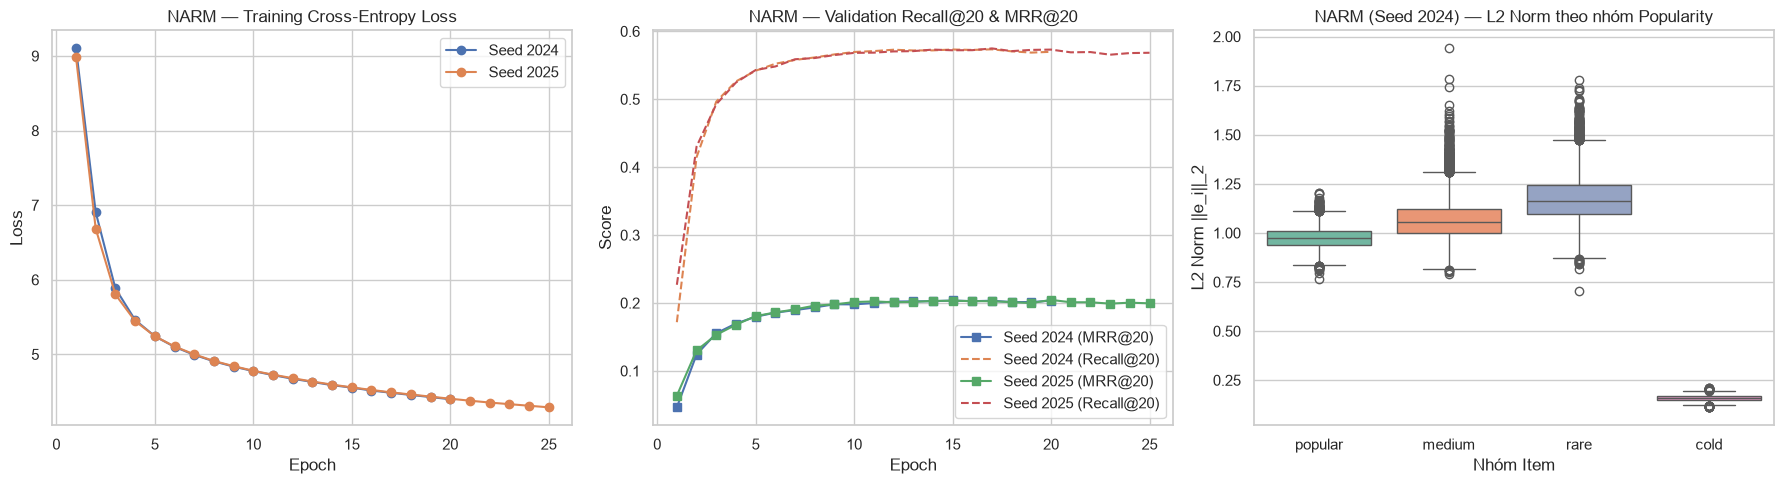

,seed,file,exists,size_kb
0,2024,config.yaml,True,3.4800
1,2024,checkpoint.pth,True,"9,920.9900"
2,2024,training.log,True,4.5700
3,2024,training_history.csv,True,2.5100
4,2024,test_metrics.json,True,5.0000
5,2024,top20.parquet,True,"6,344.2300"
6,2024,item_embeddings.npy,True,"9,395.8800"
7,2024,item_embedding_mapping.csv,True,"2,066.2000"
8,2025,config.yaml,True,3.4800
9,2025,checkpoint.pth,True,"9,920.9900"


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for seed, out in run_outputs.items():
    hist = out["history_df"]
    axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label=f"Seed {seed}")
    axes[1].plot(hist["epoch"], hist["validation_mrr@20"], marker="s", label=f"Seed {seed} (MRR@20)")
    axes[1].plot(hist["epoch"], hist["validation_recall@20"], linestyle="--", label=f"Seed {seed} (Recall@20)")

axes[0].set_title("NARM — Training Cross-Entropy Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("NARM — Validation Recall@20 & MRR@20")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()

first_seed = CONFIG["seeds"][0]
il_df = run_outputs[first_seed]["item_level_df"]
sns.boxplot(
    data=il_df,
    x="popularity_group",
    y="embedding_norm",
    order=["popular", "medium", "rare", "cold"],
    palette="Set2",
    ax=axes[2],
)
axes[2].set_title(f"NARM (Seed {first_seed}) — L2 Norm theo nhóm Popularity")
axes[2].set_xlabel("Nhóm Item")
axes[2].set_ylabel("L2 Norm ||e_i||_2")

plt.tight_layout()
plt.show()

REQUIRED_FILES = [
    "config.yaml",
    "checkpoint.pth",
    "training.log",
    "training_history.csv",
    "test_metrics.json",
    "top20.parquet",
    "item_embeddings.npy",
    "item_embedding_mapping.csv",
]

manifest_rows = []
for seed, out in run_outputs.items():
    rdir = out["run_dir"]
    for fname in REQUIRED_FILES:
        fpath = rdir / fname
        manifest_rows.append({
            "seed": seed,
            "file": fname,
            "exists": fpath.is_file(),
            "size_kb": round(fpath.stat().st_size / 1024.0, 2) if fpath.is_file() else 0.0,
        })

manifest_df = pd.DataFrame(manifest_rows)
assert manifest_df["exists"].all(), "Thiếu file bàn giao trong runs/narm!"
display(manifest_df)